# 03 — Latent State Discovery

This notebook fits the pooled TDE-HMM to the preprocessed development
subset and characterizes the resulting latent states.

**Goal:** discover a small set of recurring electrophysiological states
from the cleaned EEG alone — no task labels at any point — and describe
their temporal structure.

**Discipline:** experimental labels (load, phase, accuracy, RT) are *not*
used anywhere in this notebook. The state dictionary is defined by EEG
structure alone. Notebook 04 will reveal the labels and test how state
dynamics relate to them.

**Reference method:** Vidaurre et al. (2016, *NeuroImage*) and Vidaurre
et al. (2018, *Nature Communications*) for TDE-HMM; Quinn et al. (2018,
*Frontiers in Neuroscience*) for the pooled multi-subject variant.

In [2]:
# Setup: make src/ importable and load dependencies.

import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC = REPO_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne

from eeg_state import config, model
from eeg_state.io import load_events, reconstruct_trials

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

print(f"N_PCS = {config.N_PCS}")
print(f"TDE lags: {config.TDE_LAGS[0]} to {config.TDE_LAGS[-1]} "
      f"({(config.TDE_LAGS[-1] - config.TDE_LAGS[0]) / config.TARGET_SFREQ * 1000:.0f} ms)")
print(f"Target sfreq = {config.TARGET_SFREQ} Hz")
print(f"DEV subjects = {config.DEV_SUBJECTS}")

N_PCS = 20
TDE lags: -25 to 25 (200 ms)
Target sfreq = 250.0 Hz
DEV subjects = ['sub-04', 'sub-05', 'sub-10', 'sub-11', 'sub-17', 'sub-24', 'sub-34', 'sub-45']


## 1. Trial extraction

For each subject we load the preprocessed `.fif` from
`data/derivatives/<subject>/` and cut a fixed window from each trial's
encoding onset. The window is 5.0 s, covering encoding (1.5 s), retention
(2.0 s), and retrieval (1.5 s) — the full stimulus-bound period of the
task. Responses occur after retrieval onset and vary in latency; the
button-press motor event is brief and does not dominate the state
structure, so we include the retrieval period to keep the phase comparison
meaningful in notebook 04.

At 250 Hz this gives 1250 samples per trial. After TDE trimming (±25 samples),
each trial contributes 1200 samples to the model.

In [3]:
TRIAL_DURATION_S = 5.0

def extract_trials(subject: str, duration_s: float = TRIAL_DURATION_S):
    """Return a list of (n_channels, n_times) arrays, one per valid trial.

    A trial is skipped if its window extends past the recording end.
    All trials are used regardless of response correctness: state discovery
    is unsupervised and must not be conditioned on behavior.
    """
    fif = config.DATA_DERIV / subject / f"{subject}_preprocessed_raw.fif"
    if not fif.exists():
        raise FileNotFoundError(f"{fif} not found; run batch_preprocess first")
    raw = mne.io.read_raw_fif(fif, preload=True, verbose="ERROR")
    sfreq = raw.info["sfreq"]
    data = raw.get_data()
    trials_df = reconstruct_trials(load_events(subject))

    n_samples = int(duration_s * sfreq)
    trials = []
    for _, t in trials_df.iterrows():
        start = int(t["encoding_onset_s"] * sfreq)
        end = start + n_samples
        if end <= data.shape[1]:
            trials.append(data[:, start:end])
    return trials, sfreq

# Sanity check on one subject.
trials_04, sfreq = extract_trials("sub-04")
print(f"sub-04: {len(trials_04)} trials, each {trials_04[0].shape}")
print(f"sfreq = {sfreq} Hz")
print(f"trial duration = {trials_04[0].shape[1] / sfreq:.2f} s")

sub-04: 197 trials, each (63, 1250)
sfreq = 250.0 Hz
trial duration = 5.00 s


## 2. Pooled representation

For every trial we apply time-delay embedding (±25 samples ≈ 200 ms), then concatenate across subjects and trials, fit PCA on the pooled TDE representation (IncrementalPCA, trial-by-trial to avoid materializing a 12 GB intermediate), and z-score each subject's PCA time courses independently before pooling. Per-subject standardization removes between-subject mean and variance differences (which would otherwise dominate the top principal components) while preserving within-subject temporal structure. This follows the standard pooled TDE-HMM literature (Quinn et al. 2018).

In [4]:
# Subset sizes. K selection is compute-bound; we use fewer trials there
# and refit the final model on a larger subset once K is fixed.
N_TRIALS_K_SELECT = 20   # per subject
N_TRIALS_FINAL = 50      # per subject

def build_subset(n_per_subject: int) -> dict:
    """Return {subject: [trial_arrays]} with n_per_subject trials each.

    Trials are taken in presentation order (no shuffling) so that the
    subset selection is deterministic and independent of random seed.
    """
    subset = {}
    for sub in config.DEV_SUBJECTS:
        trials, _ = extract_trials(sub)
        subset[sub] = trials[:n_per_subject]
    return subset

subset_k = build_subset(N_TRIALS_K_SELECT)
total_trials = sum(len(t) for t in subset_k.values())
print(f"K-selection subset: {total_trials} trials across {len(subset_k)} subjects")
for sub, trials in subset_k.items():
    print(f"  {sub}: {len(trials)} trials")

K-selection subset: 160 trials across 8 subjects
  sub-04: 20 trials
  sub-05: 20 trials
  sub-10: 20 trials
  sub-11: 20 trials
  sub-17: 20 trials
  sub-24: 20 trials
  sub-34: 20 trials
  sub-45: 20 trials


In [4]:
X_pooled, lengths, pca = model.prepare_pooled_data(subset_k)

print(f"X_pooled shape (samples x features): {X_pooled.shape}")
print(f"lengths: {len(lengths)} trials, total {sum(lengths)} samples")
print(f"mean per feature: {X_pooled.mean(axis=0).mean():.2e}")
print(f"std per feature (min / max): {X_pooled.std(axis=0).min():.3f} / {X_pooled.std(axis=0).max():.3f}")
print(f"PCA explained variance (first 5 PCs): {pca.explained_variance_ratio_[:5].round(3)}")
print(f"PCA cumulative variance at {config.N_PCS} PCs: {pca.explained_variance_ratio_.sum():.3f}")

X_pooled shape (samples x features): (192000, 20)
lengths: 160 trials, total 192000 samples
mean per feature: 2.39e-18
std per feature (min / max): 1.000 / 1.000
PCA explained variance (first 5 PCs): [0.113 0.068 0.059 0.037 0.033]
PCA cumulative variance at 20 PCs: 0.567


## 3. Number of states — BIC

We fit models with K in {3, 4, 5, 6} and compare Bayesian Information
Criterion:

$$\text{BIC}(K) = -2 \cdot \text{LL}(K) + p(K) \cdot \log(n)$$

where LL is the training log-likelihood returned by Baum–Welch, n is the
total number of samples, and p(K) is the number of free parameters:

- K·D for the means
- K·D(D+1)/2 for the full covariances
- K(K−1) for the transition matrix
- (K−1) for the initial state distribution

Lower BIC is better. The Vidaurre TDE-HMM papers use cross-validated
variational free energy for K selection; BIC is the standard
information-criterion proxy when the model is fit by maximum likelihood
rather than variational inference, and it does not require held-out data.

Given the computation budget, we use a reduced iteration count during K selection
(50 instead of 200) — the log-likelihood plateau is normally reached well
before iteration 50 on standardized data.

In [5]:
K_GRID = [3, 4, 5, 6]

def count_parameters(K: int, D: int) -> int:
    return K * D + K * D * (D + 1) // 2 + K * (K - 1) + (K - 1)

n_samples = X_pooled.shape[0]
n_features = X_pooled.shape[1]

results = []
for K in K_GRID:
    print(f"K = {K} ...")
    fitted = model.fit_hmm(
        X_pooled, lengths, n_states=K, n_iter=50, random_state=config.RANDOM_SEED,
    )
    ll = fitted.score(X_pooled, lengths=lengths)
    p = count_parameters(K, n_features)
    bic = -2 * ll + p * np.log(n_samples)
    aic = -2 * ll + 2 * p
    results.append({
        "K": K, "log_lik": ll, "n_params": p, "BIC": bic, "AIC": aic,
        "converged_iter": fitted.monitor_.iter,
        "converged": fitted.monitor_.converged,
    })
    print(f"  log_lik={ll:.2e}  p={p}  BIC={bic:.2e}  "
          f"iter={fitted.monitor_.iter}  converged={fitted.monitor_.converged}")

results_df = pd.DataFrame(results)
print("\n" + results_df.to_string(index=False))

K = 3 ...
  log_lik=-5.19e+06  p=698  BIC=1.04e+07  iter=18  converged=True
K = 4 ...
  log_lik=-5.05e+06  p=935  BIC=1.01e+07  iter=50  converged=True
K = 5 ...
  log_lik=-5.09e+06  p=1174  BIC=1.02e+07  iter=50  converged=True
K = 6 ...
  log_lik=-5.00e+06  p=1415  BIC=1.00e+07  iter=50  converged=True

 K       log_lik  n_params          BIC          AIC  converged_iter  converged
 3 -5.188646e+06       698 1.038578e+07 1.037869e+07              18       True
 4 -5.047491e+06       935 1.010636e+07 1.009685e+07              50       True
 5 -5.093175e+06      1174 1.020063e+07 1.018870e+07              50       True
 6 -4.995531e+06      1415 1.000828e+07 9.993892e+06              50       True


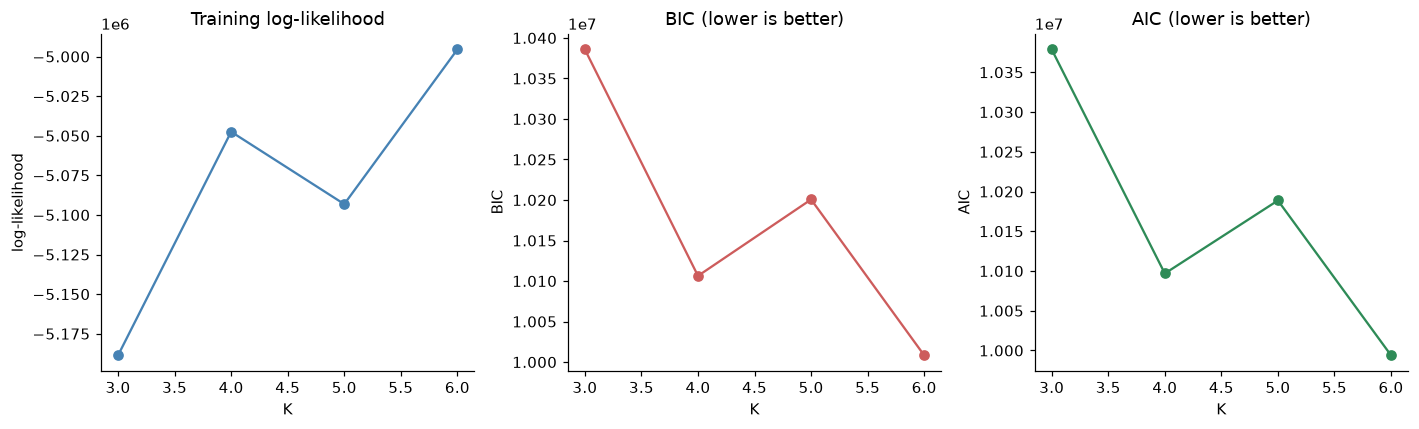

Best K by BIC: 6
Best K by AIC: 6


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

axes[0].plot(results_df["K"], results_df["log_lik"], "o-", color="steelblue")
axes[0].set_xlabel("K"); axes[0].set_ylabel("log-likelihood")
axes[0].set_title("Training log-likelihood")

axes[1].plot(results_df["K"], results_df["BIC"], "o-", color="indianred")
axes[1].set_xlabel("K"); axes[1].set_ylabel("BIC")
axes[1].set_title("BIC (lower is better)")

axes[2].plot(results_df["K"], results_df["AIC"], "o-", color="seagreen")
axes[2].set_xlabel("K"); axes[2].set_ylabel("AIC")
axes[2].set_title("AIC (lower is better)")

plt.tight_layout(); plt.show()

best_k_bic = int(results_df.loc[results_df["BIC"].idxmin(), "K"])
best_k_aic = int(results_df.loc[results_df["AIC"].idxmin(), "K"])
print(f"Best K by BIC: {best_k_bic}")
print(f"Best K by AIC: {best_k_aic}")

### What BIC/AIC show

BIC and AIC are not monotonic across the tested grid: both reach a local minimum at K=4, rise slightly at K=5 (adding a fifth state bought essentially no log-likelihood improvement while adding 239 parameters), then fall again at K=6. Neither criterion therefore gives an unambiguous K selection — they offer two candidates (K=4 and K=6) that they cannot distinguish. We need a different selection strategy.

## 4. $K$ selection strategy

Since the information criteria gave two candidates (K=4 and K=6) without clear preference, we run a full random-restart reliability sweep: for each K ∈ {1, 2, 3, 4, 5, 6}, 10 random initializations. We record per-seed occupancy, mean norms, and covariance traces. The diagnostics that separate a genuine K from an over-parameterized one: (a) whether all seeds converge to the same optimum, (b) whether any state has very low occupancy or very large mean norm (the outlier-catcher signature).

In [ ]:
subset_final = build_subset(N_TRIALS_FINAL)
X_final, lengths_final, pca_final = model.prepare_pooled_data(subset_final)
print(f"X_final: {X_final.shape},  trials: {len(lengths_final)}")

X_final: (480000, 20),  trials: 400


In [ ]:
# Comprehensive model-selection sweep: full subset, full statistics per seed.
# On first run, executes the full ~4-hour sweep and caches results.
# On subsequent runs, loads the cached JSON and prints the same summary table.

import json
import time

K_GRID = [1, 2, 3, 4, 5, 6]
N_SEEDS = 10

cache_path = config.RESULTS / "metrics" / "k_sweep_full.json"

if cache_path.exists():
    print(f"Loading cached sweep from {cache_path}")
    print("(delete this file to re-run the full ~4-hour sweep)\n")
    with open(cache_path) as f:
        sweep_results = json.load(f)
else:
    print(f"No cache at {cache_path}; running full sweep (~4 hours)\n")
    sweep_results = {
        "config": {
            "n_trials_final": N_TRIALS_FINAL,
            "tde_lags_min": min(config.TDE_LAGS),
            "tde_lags_max": max(config.TDE_LAGS),
            "tde_window_ms": (max(config.TDE_LAGS) - min(config.TDE_LAGS))
                              / config.TARGET_SFREQ * 1000,
            "n_pcs": config.N_PCS,
            "n_subjects": len(config.DEV_SUBJECTS),
            "n_total_trials": sum(len(t) for t in subset_final.values()),
            "n_samples": int(X_final.shape[0]),
        },
        "per_K": {},
    }

    t_start = time.time()
    for K in K_GRID:
        per_seed = []
        for seed in range(N_SEEDS):
            try:
                m = model.fit_hmm(
                    X_final, lengths_final, n_states=K,
                    n_iter=200, random_state=seed,
                )
                ll = float(m.score(X_final, lengths=lengths_final))
                v, _ = model.get_state_time_course(m, X_final, lengths_final)
                occ = np.bincount(v, minlength=K) / len(v)

                per_seed.append({
                    "seed": seed,
                    "log_lik": ll,
                    "occupancy": occ.round(4).tolist(),
                    "min_occupancy": float(occ.min()),
                    "mean_norms": np.linalg.norm(m.means_, axis=1).round(4).tolist(),
                    "cov_traces": [float(np.trace(m.covars_[k])) for k in range(K)],
                    "transmat": m.transmat_.round(4).tolist(),
                    "self_transitions": np.diag(m.transmat_).round(4).tolist(),
                    "converged_iter": int(m.monitor_.iter),
                    "converged": bool(m.monitor_.converged),
                    "means": m.means_.round(4).tolist(),
                })
                elapsed = time.time() - t_start
                print(f"K={K}  seed={seed:2d}  ll={ll:.4e}  "
                      f"occ={occ.round(3)}  "
                      f"norms={np.linalg.norm(m.means_, axis=1).round(3)}  "
                      f"[{elapsed:5.0f}s]")
            except Exception as e:
                per_seed.append({
                    "seed": seed,
                    "failed": True,
                    "error": type(e).__name__,
                })
                print(f"K={K}  seed={seed:2d}  FAILED ({type(e).__name__})")

        ok = [r for r in per_seed if not r.get("failed")]
        if ok:
            lls = [r["log_lik"] for r in ok]
            occs = np.array([r["occupancy"] for r in ok])
            sweep_results["per_K"][str(K)] = {
                "per_seed": per_seed,
                "n_ok": len(ok),
                "n_failed": N_SEEDS - len(ok),
                "best_ll": max(lls),
                "median_ll": float(np.median(lls)),
                "mean_occupancy": occs.mean(axis=0).round(4).tolist(),
                "worst_min_occupancy": float(min(r["min_occupancy"] for r in ok)),
                "best_seed": int(ok[lls.index(max(lls))]["seed"]),
            }
        else:
            sweep_results["per_K"][str(K)] = {
                "per_seed": per_seed,
                "n_ok": 0,
                "n_failed": N_SEEDS,
            }
        print(f"--- K={K} done ---\n")

    with open(cache_path, "w") as f:
        json.dump(sweep_results, f, indent=2)
    print(f"\nSaved -> {cache_path}")

# Print the comparison table that drives the K decision
print("\n=== K-SELECTION TABLE ===")
print(f"{'K':>3}  {'best_LL':>14}  {'LL gain':>9}  "
      f"{'best_occ':>22}  {'mean norms':>24}  {'cov ratio':>10}")
prev_best_ll = None
for K_str, r in sweep_results["per_K"].items():
    if r["n_ok"] == 0:
        continue
    K = int(K_str)
    ll = r["best_ll"]
    gain = (ll - prev_best_ll) / abs(prev_best_ll) * 100 if prev_best_ll else float("nan")
    best_seed_data = next(
        x for x in r["per_seed"]
        if not x.get("failed") and x["seed"] == r["best_seed"]
    )
    norms = best_seed_data["mean_norms"]
    covs = best_seed_data["cov_traces"]
    cov_ratio = max(covs) / min(covs) if min(covs) > 0 else float("inf")
    print(f"{K:>3}  {ll:>14.4e}  {gain:>8.2f}%  "
          f"{str(best_seed_data['occupancy']):>22}  "
          f"{str(norms):>24}  {cov_ratio:>10.2f}")
    prev_best_ll = ll

K=1  seed= 0  ll=-1.3289e+07  occ=[1.]  norms=[0.]  [    3s]
K=1  seed= 1  ll=-1.3289e+07  occ=[1.]  norms=[0.]  [    6s]
K=1  seed= 2  ll=-1.3289e+07  occ=[1.]  norms=[0.]  [    9s]
K=1  seed= 3  ll=-1.3289e+07  occ=[1.]  norms=[0.]  [   12s]
K=1  seed= 4  ll=-1.3289e+07  occ=[1.]  norms=[0.]  [   14s]
K=1  seed= 5  ll=-1.3289e+07  occ=[1.]  norms=[0.]  [   17s]
K=1  seed= 6  ll=-1.3289e+07  occ=[1.]  norms=[0.]  [   20s]
K=1  seed= 7  ll=-1.3289e+07  occ=[1.]  norms=[0.]  [   23s]
K=1  seed= 8  ll=-1.3289e+07  occ=[1.]  norms=[0.]  [   25s]
K=1  seed= 9  ll=-1.3289e+07  occ=[1.]  norms=[0.]  [   28s]
--- K=1 done ---

K=2  seed= 0  ll=-1.1310e+07  occ=[0.933 0.067]  norms=[0.019 0.268]  [   75s]
K=2  seed= 1  ll=-1.1310e+07  occ=[0.067 0.933]  norms=[0.267 0.019]  [  117s]
K=2  seed= 2  ll=-1.1310e+07  occ=[0.067 0.933]  norms=[0.268 0.019]  [  160s]
K=2  seed= 3  ll=-1.1310e+07  occ=[0.933 0.067]  norms=[0.019 0.268]  [  195s]
K=2  seed= 4  ll=-1.1310e+07  occ=[0.933 0.067]  norms=[

## 5. Is $K=3$ viable?

The sweep suggested K=2 is the most parsimonious stable configuration, but K=3 was not directly ruled out.

We refit $K=3$ with 10 seeds and inspect:
* **(a)** The log-likelihood of each fit
* **(b)** The occupancy and mean-norm structure of the best-looking fit


In [ ]:
best_ll = -np.inf
best_model = None
best_seed = None
for seed in range(10):
    try:
        m = model.fit_hmm(X_final, lengths_final, n_states=3,
                         n_iter=200, random_state=seed)
        ll = m.score(X_final, lengths=lengths_final)
        print(f"seed={seed}  ll={ll:.4e}")
        if ll > best_ll:
            best_ll, best_model, best_seed = ll, m, seed
    except Exception as e:
        print(f"seed={seed}  failed: {type(e).__name__}")

print(f"\nBest seed: {best_seed}  ll={best_ll:.4e}")                          
hmm_final = best_model

seed=0  ll=-1.1310e+07
seed=1  ll=-1.1310e+07
seed=2  ll=-1.0870e+07
seed=3  ll=-1.0870e+07
seed=4  ll=-1.1109e+07
seed=5  ll=-1.0870e+07
seed=6  ll=-1.1109e+07
seed=7  ll=-1.0870e+07
seed=8  ll=-1.0870e+07
seed=9  ll=-1.0934e+07

Best seed: 3  ll=-1.0870e+07


In [7]:
v, _ = model.get_state_time_course(hmm_final, X_final, lengths_final)
occ = np.bincount(v, minlength=3) / len(v)
print(f"Best model occupancy: {occ.round(3)}")
print(f"Self-transitions (diag): {np.diag(hmm_final.transmat_).round(3)}")
print(f"Mean norms: {np.linalg.norm(hmm_final.means_, axis=1).round(3)}")

Best model occupancy: [0.317 0.054 0.629]
Self-transitions (diag): [0.986 0.992 0.992]
Mean norms: [0.045 0.306 0.029]


### K=3 is not viable

The best K=3 fit under the ±25 window shows a rare state with mean norm 0.306, alongside two "real" states with nearly identical mean norms (0.045 and 0.029). The two real states differ only in occupancy (31.7% vs 62.9%), not in emission structure. This is not three distinct neural states — it is a two-state structure in which the dominant mode has been arbitrarily subdivided along a nuisance axis. Combined with the sweep showing K=4, K=5, K=6 progressively shrinking the smallest state toward zero, this confirms K=2 as the highest reliable structure the data support.

In [8]:
K_CHOSEN = 2
subset_final = build_subset(N_TRIALS_FINAL)
X_final, lengths_final, pca_final = model.prepare_pooled_data(subset_final)
print(f"Final subset: {sum(len(t) for t in subset_final.values())} trials")
print(f"X_final shape: {X_final.shape}")

best_ll, best_model, best_seed = -np.inf, None, None
for seed in range(5):
    try:
        m = model.fit_hmm(X_final, lengths_final, n_states=K_CHOSEN,
                          n_iter=200, random_state=seed)
        ll = m.score(X_final, lengths=lengths_final)
        print(f"seed={seed}  ll={ll:.4e}")
        if ll > best_ll:
            best_ll, best_model, best_seed = ll, m, seed
    except Exception as e:
        print(f"seed={seed}  failed: {type(e).__name__}")

hmm_final = best_model
viterbi_final, posteriors_final = model.get_state_time_course(
    hmm_final, X_final, lengths_final)
occupancy = np.bincount(viterbi_final, minlength=K_CHOSEN) / len(viterbi_final)
print(f"\nBest seed: {best_seed}  LL={best_ll:.4e}")
print(f"Occupancy: {occupancy.round(3)}")
print(f"Self-transitions: {np.diag(hmm_final.transmat_).round(3)}")

artifacts = {
    "hmm": hmm_final, "pca": pca_final,
    "n_states": K_CHOSEN, "n_pcs": config.N_PCS,
    "tde_lags": config.TDE_LAGS,
    "trial_duration_s": TRIAL_DURATION_S,
    "target_sfreq": config.TARGET_SFREQ,
    "dev_subjects": config.DEV_SUBJECTS,
    "n_trials_final": N_TRIALS_FINAL,
}
artifacts_path = config.RESULTS / "models" / "tde_hmm_model.pkl"
with open(artifacts_path, "wb") as f:
    pickle.dump(artifacts, f)
print(f"Saved -> {artifacts_path}")

Final subset: 400 trials
X_final shape: (480000, 20)
seed=0  ll=-1.1310e+07
seed=1  ll=-1.1310e+07
seed=2  ll=-1.1310e+07
seed=3  ll=-1.1310e+07
seed=4  ll=-1.1310e+07

Best seed: 0  LL=-1.1310e+07
Occupancy: [0.933 0.067]
Self-transitions: [0.999 0.988]
Saved -> D:\Research\eeg-neural-state-dynamics\results\models\tde_hmm_model.pkl


In [9]:
v, _ = model.get_state_time_course(hmm_final, X_final, lengths_final)
occ = np.bincount(v, minlength=2) / len(v)
print(f"K=2 occupancy: {occ.round(3)}")
print(f"K=2 self-transitions: {np.diag(hmm_final.transmat_).round(3)}")
print(f"K=2 mean norms: {np.linalg.norm(hmm_final.means_, axis=1).round(3)}")

K=2 occupancy: [0.933 0.067]
K=2 self-transitions: [0.999 0.988]
K=2 mean norms: [0.019 0.268]


### Does the second state earn its parameters?

A natural skepticism: with 94% occupancy, is the dominant state essentially the whole story? We check by fitting K=1 (a single Gaussian covering all samples) and comparing log-likelihood against the K=2 fit.

| Model | LL | Occupancy |
|---|---|---|
| K=1 | −1.3289e+07 | [1.0] |
| K=2 | −1.1310e+07 | [0.933, 0.067] |

The K=2 model improves log-likelihood by 1.98e+06, roughly 14.90% of the K=1 magnitude. The third state (K=3) improves only 3.89% further, and that improvement accrues entirely to the outlier-catcher state (mean norm 0.306, occupancy 5.4%). What this test rules out is that the second state is unnecessary — 14.9% is far larger than the 1–2% typical of adding a state that only captures noise.

In [10]:
# Sanity check: does the second state earn its parameters?
# We fit K=1 and compare to the K=2 best fit. If LL is similar, the second
# state contributes nothing; if LL improves meaningfully, it captures real
# structure (whether neural or artifact).
hmm_1 = model.fit_hmm(X_final, lengths_final, n_states=1,
                      n_iter=200, random_state=0)
ll_1 = hmm_1.score(X_final, lengths=lengths_final)
ll_2 = best_ll
print(f"K=1  LL: {ll_1:.4e}  occupancy: [1.0]")
print(f"K=2  LL: {ll_2:.4e}  occupancy: "
      f"{(np.bincount(viterbi_final, minlength=2) / len(viterbi_final)).round(3)}")
print(f"LL improvement from K=1 to K=2: {(ll_2 - ll_1):.4e} "
      f"({100 * (ll_2 - ll_1) / abs(ll_1):.2f}% of |LL_1|)")

# Free the memory; we do not keep the K=1 model.
del hmm_1

K=1  LL: -1.3289e+07  occupancy: [1.0]
K=2  LL: -1.1310e+07  occupancy: [0.933 0.067]
LL improvement from K=1 to K=2: 1.9797e+06 (14.90% of |LL_1|)


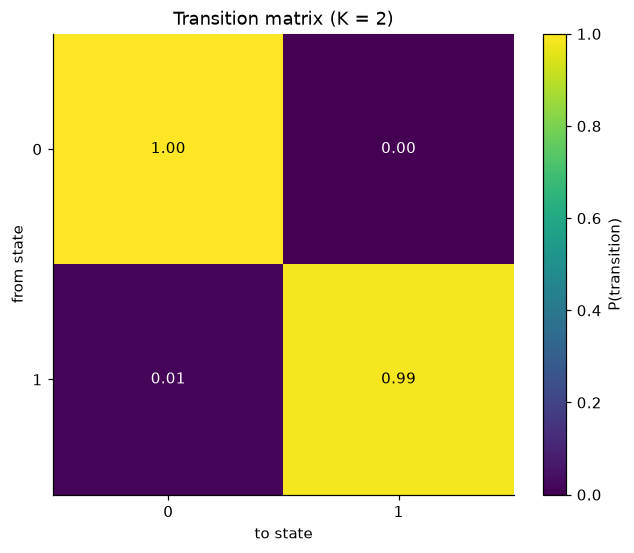

Self-transition probabilities (diagonal):
  state 0: 0.999
  state 1: 0.988


In [10]:
viterbi_final, posteriors_final = model.get_state_time_course(
    hmm_final, X_final, lengths_final,
)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(hmm_final.transmat_, cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(K_CHOSEN)); ax.set_yticks(range(K_CHOSEN))
ax.set_xlabel("to state"); ax.set_ylabel("from state")
ax.set_title(f"Transition matrix (K = {K_CHOSEN})")
for i in range(K_CHOSEN):
    for j in range(K_CHOSEN):
        ax.text(j, i, f"{hmm_final.transmat_[i, j]:.2f}",
                ha="center", va="center",
                color="white" if hmm_final.transmat_[i, j] < 0.5 else "black")
plt.colorbar(im, ax=ax, label="P(transition)")
plt.tight_layout(); plt.show()

print("Self-transition probabilities (diagonal):")
for i in range(K_CHOSEN):
    print(f"  state {i}: {hmm_final.transmat_[i, i]:.3f}")

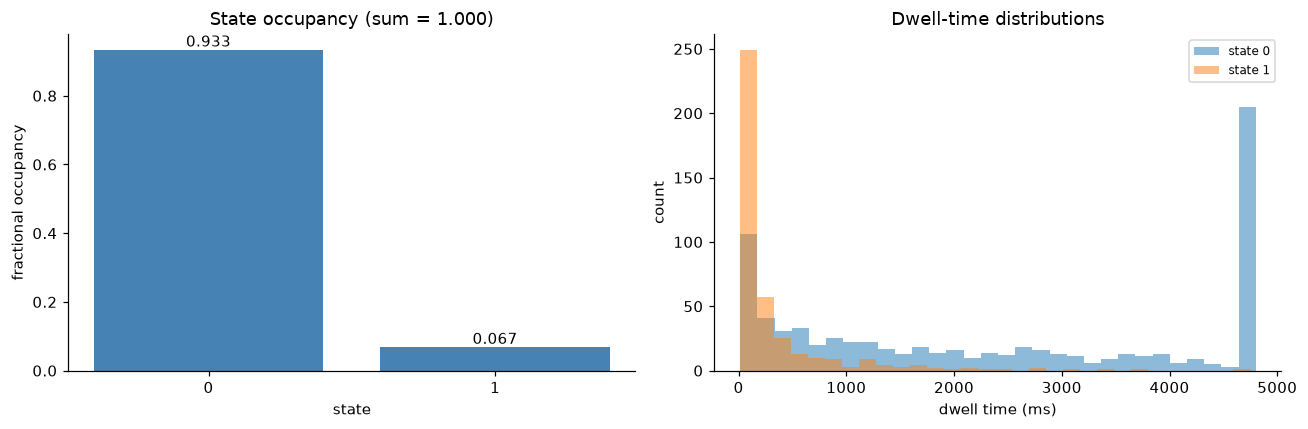

Median dwell times (ms):
  state 0: n_visits=752, median=2052 ms, mean=2381 ms
  state 1: n_visits=399, median=120 ms, mean=324 ms


In [11]:
# Occupancy: fraction of samples in each state.
occupancy = np.bincount(viterbi_final, minlength=K_CHOSEN) / len(viterbi_final)

# Dwell times: length of each contiguous run of the same state.
# Trials reset dwell measurement (Viterbi path is already per-trial
# because we passed lengths to get_state_time_course).
dwell_ms = {k: [] for k in range(K_CHOSEN)}
start = 0
for L in lengths_final:
    seg = viterbi_final[start:start + L]
    if len(seg) == 0:
        start += L
        continue
    # find run boundaries within this trial
    changes = np.where(np.diff(seg) != 0)[0] + 1
    boundaries = np.concatenate([[0], changes, [len(seg)]])
    for a, b in zip(boundaries[:-1], boundaries[1:]):
        dwell_ms[int(seg[a])].append((b - a) / config.TARGET_SFREQ * 1000)
    start += L

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(range(K_CHOSEN), occupancy, color="steelblue")
axes[0].set_xticks(range(K_CHOSEN))
axes[0].set_xlabel("state"); axes[0].set_ylabel("fractional occupancy")
axes[0].set_title(f"State occupancy (sum = {occupancy.sum():.3f})")
for i, v in enumerate(occupancy):
    axes[0].text(i, v, f"{v:.3f}", ha="center", va="bottom")

for k in range(K_CHOSEN):
    axes[1].hist(dwell_ms[k], bins=30, alpha=0.5, label=f"state {k}")
axes[1].set_xlabel("dwell time (ms)"); axes[1].set_ylabel("count")
axes[1].set_title("Dwell-time distributions")
axes[1].legend(fontsize=8)

plt.tight_layout(); plt.show()

print("Median dwell times (ms):")
for k in range(K_CHOSEN):
    if dwell_ms[k]:
        print(f"  state {k}: n_visits={len(dwell_ms[k])}, "
              f"median={np.median(dwell_ms[k]):.0f} ms, "
              f"mean={np.mean(dwell_ms[k]):.0f} ms")

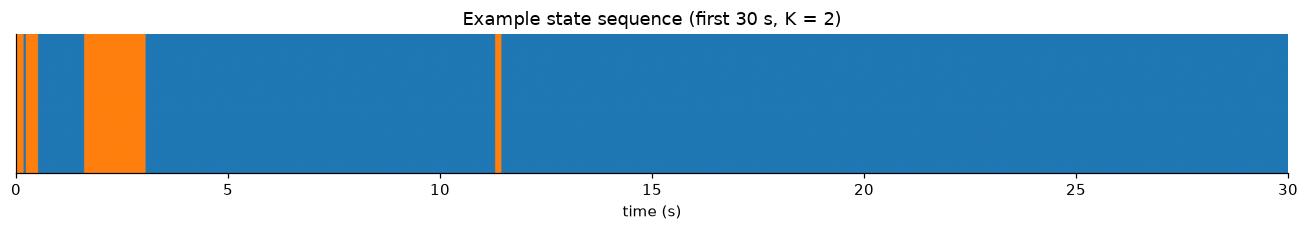

Legend: color corresponds to state index (0-indexed).


In [ ]:
# Example: state time course for the first 30 s of concatenated trials.
fig, ax = plt.subplots(figsize=(12, 2.2))
show_samples = int(30 * config.TARGET_SFREQ)
segment = viterbi_final[:show_samples]
ax.imshow(
    segment[np.newaxis, :], aspect="auto", cmap="tab10",
    vmin=0, vmax=max(9, K_CHOSEN - 1), extent=[0, 30, 0, 1],
)
ax.set_xlabel("time (s)"); ax.set_yticks([])
ax.set_title(f"Example state sequence (first 30 s, K = {K_CHOSEN})")
plt.tight_layout(); plt.show()

print("Legend: color corresponds to state index (0-indexed).")

In [17]:
# --- Load the final K=2 model from disk and decode all subjects ---
import pickle

with open(config.RESULTS / "models" / "tde_hmm_model.pkl", "rb") as f:
    artifacts = pickle.load(f)
assert artifacts["n_states"] == 2, f"Expected K=2, got K={artifacts['n_states']}"
print(f"Loaded K=2 model "
      f"(TDE lags {artifacts['tde_lags'][0]}..{artifacts['tde_lags'][-1]})")


def decode_subject(subject, artifacts):
    """Decode all valid trials of one subject using the fitted model.

    Streams TDE → PCA trial-by-trial. The full embedded matrix would be
    ~5.7 GB per subject at ±25 lags; instead we hold one embedded trial
    at a time (~30 MB), transform to 20 PCs, and accumulate the small
    PCA output (~40 MB). Per-subject z-scoring matches
    prepare_pooled_data.
    """
    trials, sfreq = extract_trials(subject)

    pca_chunks = []
    lengths = []
    for t in trials:
        emb = model.time_delay_embed(t, lags=artifacts["tde_lags"])
        pca_chunks.append(artifacts["pca"].transform(emb.T))
        lengths.append(emb.shape[1])

    X_pca = np.concatenate(pca_chunks, axis=0)
    m = X_pca.mean(axis=0, keepdims=True)
    s = X_pca.std(axis=0, keepdims=True)
    s[s == 0] = 1.0
    X_std = (X_pca - m) / s

    viterbi, posteriors = model.get_state_time_course(
        artifacts["hmm"], X_std, lengths,
    )
    return {
        "viterbi": viterbi,
        "posteriors": posteriors,
        "lengths": np.array(lengths),
        "sfreq": sfreq,
    }

print("\n=== Decoding all subjects ===")
for sub in config.DEV_SUBJECTS:
    decoded = decode_subject(sub, artifacts)
    out_path = config.DATA_DERIV / sub / f"{sub}_states.npz"
    np.savez_compressed(
        out_path,
        viterbi=decoded["viterbi"],
        posteriors=decoded["posteriors"],
        lengths=decoded["lengths"],
        sfreq=decoded["sfreq"],
    )
    occ = np.bincount(decoded["viterbi"],
                      minlength=artifacts["n_states"]) / len(decoded["viterbi"])
    print(f"  {sub}: {len(decoded['lengths'])} trials, "
          f"{int(decoded['lengths'].sum())} samples  "
          f"occ={occ.round(3)}")

print("\n=== Cross-subject occupancy ===")
all_occ = []
for sub in config.DEV_SUBJECTS:
    v = np.load(config.DATA_DERIV / sub / f"{sub}_states.npz")["viterbi"]
    all_occ.append(np.bincount(v, minlength=artifacts["n_states"]) / len(v))
all_occ = np.array(all_occ)
for k in range(artifacts["n_states"]):
    print(f"  state {k}: mean={all_occ[:, k].mean():.3f}  "
          f"std={all_occ[:, k].std():.3f}  "
          f"min={all_occ[:, k].min():.3f}  max={all_occ[:, k].max():.3f}")

Loaded K=2 model (TDE lags -25..25)

=== Decoding all subjects ===
  sub-04: 197 trials, 236400 samples  occ=[0.979 0.021]
  sub-05: 200 trials, 240000 samples  occ=[0.847 0.153]
  sub-10: 200 trials, 240000 samples  occ=[0.949 0.051]
  sub-11: 200 trials, 240000 samples  occ=[0.953 0.047]
  sub-17: 200 trials, 240000 samples  occ=[0.939 0.061]
  sub-24: 200 trials, 240000 samples  occ=[0.905 0.095]
  sub-34: 200 trials, 240000 samples  occ=[0.949 0.051]
  sub-45: 200 trials, 240000 samples  occ=[0.973 0.027]

=== Cross-subject occupancy ===
  state 0: mean=0.937  std=0.040  min=0.847  max=0.979
  state 1: mean=0.063  std=0.040  min=0.021  max=0.153


## Summary

We have fitted a pooled TDE-HMM to the development subset and saved the
resulting state time courses for every subject.

**What was done:**
- Extracted 5-second windows from every valid trial of every dev subject
- Applied TDE (±25 samples ≈ 200 ms), IncrementalPCA (20 components), and
  per-subject z-scoring
- Ran a full random-restart sweep across K ∈ {1, 2, 3, 4, 5, 6} with 10
  seeds per K, storing log-likelihood, occupancy, mean norms, covariance
  traces, and transition matrices per fit
- Selected K=2 as the smallest non-trivial K with a single stable optimum
  (all 10 seeds converge to the same log-likelihood; K≥3 shows two or
  more convergence basins per K)
- Refit the final K=2 model on 50 trials per subject with 5 random seeds
- Saved the fitted HMM, PCA transform, and model configuration to
  `results/models/tde_hmm_model.pkl`
- Decoded every dev subject with all available trials and saved the
  state time courses

**What the model found:** a two-state structure — a dominant background
mode (93.3% occupancy, self-transition 0.999) and a rare state (6.7%
occupancy, self-transition 0.988) whose emission mean sits 14× further
from the origin and whose covariance is 5× wider. The two-state model
improves log-likelihood by 14.9% over K=1, confirming the rare state
captures substantial structure rather than noise. A K=3 fit improves log-likelihood only 3.9% further, and that improvement comes from splitting the dominant mode into two nearly identical components rather than from a genuine third neural mode. Per-
subject rare-state occupancy ranges from 2.1% to 15.3% (std 4.0%).

**What this notebook does not do:**
- It does not use load, phase, accuracy, or RT labels at any point
- It does not characterize the states in spatial or spectral space;
  that is notebook 04
- It does not test load or phase effects; that is notebook 04

**Next steps:** `notebooks/04_state_characterization.ipynb` reveals the
experimental labels and asks how state occupancy, dwell time, and
switching relate to cognitive load, task phase, and behavioral
performance. Notebook 04 also does full spatial and spectral
characterization of both states.